# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `S3_Online_Retail_Explorado.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | Freddy Antonio Arias Adasme |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [44]:
# Configuración inicial — Laboratorio 4

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20264

np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

print('Listo')

Listo


---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [45]:
df = pd.read_csv(RUTA + 'S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

Líneas: 21494 · Transacciones: 4000 · Productos: 21


,transaccion_id,fecha,tienda,producto
0,T00001,2025-03-02,Norte,pan
1,T00001,2025-03-02,Norte,vino
2,T00002,2025-06-22,Oriente,azucar
3,T00002,2025-06-22,Oriente,cafe
4,T00002,2025-06-22,Oriente,fideos


**Interpretación — Carga del conjunto transaccional**

El conjunto contiene 21.494 registros correspondientes a 4.000 transacciones y 21 productos diferentes. Cada registro representa un producto asociado a una transacción, por lo que una misma compra puede aparecer en varias filas.

Esta estructura permite realizar un análisis de reglas de asociación, identificando productos que suelen adquirirse conjuntamente.

### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

In [46]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]

Matriz: (4000, 21)


producto,arroz,azucar,cafe,cerveza,detergente,fideos
transaccion_id,,,,,,
T00001,False,False,False,False,False,False
T00002,False,True,True,False,False,True
T00003,False,True,False,True,False,False
T00004,True,False,False,False,False,False
T00005,False,True,False,False,False,False


**Interpretación — Construcción de la matriz de canastas**

Se transformó el conjunto transaccional original en una matriz de 4.000 filas y 21 columnas. Cada fila representa una transacción y cada columna corresponde a un producto.

Los valores booleanos indican si un producto está presente (True) o ausente (False) en una determinada transacción.

Esta transformación permite aplicar algoritmos de reglas de asociación, como Apriori, para identificar combinaciones frecuentes de productos.

In [47]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(8).round(3)

,0
producto,
pan,0.622
leche,0.566
palta,0.462
azucar,0.321
salsa de tomate,0.304
huevos,0.294
jamon,0.240
arroz,0.238


«pan» aparece en el 62 % de las canastas y «leche» en el 57 %. **Retén ese dato**: explica lo que viene a continuación.

**Interpretación — Frecuencia de los productos**

El pan es el producto más frecuente, presente en el 62,2 % de las transacciones, seguido de la leche con un 56,6 % y la palta con un 46,2 %.

Estos resultados muestran que algunos productos aparecen con mayor frecuencia en las canastas. Sin embargo, esto no significa necesariamente que exista una asociación entre ellos.

Por esta razón, es importante analizar también el soporte, la confianza y el lift, para distinguir las asociaciones relevantes de aquellas que pueden explicarse por la frecuencia individual de los productos.

### 1.2 Extraer las reglas

In [48]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True)
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10)

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0]))
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 205


**Interpretación — Extracción de reglas de asociación**

Se aplicó el algoritmo Apriori utilizando un soporte mínimo de 0,05 y una confianza mínima de 0,10. Posteriormente, se seleccionaron las reglas con un producto en el antecedente y otro en el consecuente.

El procedimiento permitió identificar 205 reglas de asociación, que representan posibles relaciones de compra entre los 21 productos del conjunto transaccional.

Sin embargo, la cantidad de reglas encontradas no significa que todas sean comercialmente relevantes. Para identificar las asociaciones más significativas es necesario comparar el soporte, la confianza y especialmente el lift.

Un lift superior a 1 indica una asociación positiva entre productos, mientras que valores cercanos a 1 sugieren que la relación puede explicarse principalmente por sus frecuencias individuales.

### 1.3 La trampa: ordenar por confianza

In [49]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
156,palta → pan,0.392,0.850,1.368
89,fideos → salsa de tomate,0.172,0.783,2.573
21,cafe → azucar,0.147,0.747,2.327
69,cerveza → papas fritas,0.098,0.667,2.830
74,detergente → pan,0.079,0.656,1.056
186,tomate → pan,0.133,0.645,1.038
57,cafe → pan,0.127,0.643,1.035
182,queso → pan,0.144,0.637,1.024


Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

**Interpretación — Reglas ordenadas por confianza**

Al ordenar las reglas por confianza, se observa que algunas asociaciones presentan probabilidades condicionales elevadas, pero no todas tienen la misma relevancia.

Por ejemplo, la regla **palta -> pan** presenta una confianza de 0,850 y un lift de 1,368, indicando una asociación positiva. En cambio, **fideos -> salsa de tomate** tiene una confianza de 0,783 y un lift de 2,573, lo que representa una asociación relativamente más fuerte respecto de lo esperado por las frecuencias individuales.

La regla **detergente -> pan** presenta una confianza de 0,656, pero su lift es de solo 1,056. Esto significa que la presencia de detergente apenas aumenta la probabilidad de encontrar pan respecto de su frecuencia general.

Por lo tanto, la confianza por sí sola puede resultar engañosa, especialmente cuando el producto consecuente es muy frecuente. Es necesario complementarla con el soporte y el lift antes de interpretar una regla como comercialmente relevante.

### 1.4 El mismo cálculo, ordenado por lift

In [50]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
68,papas fritas → cerveza,0.098,0.415,2.830
69,cerveza → papas fritas,0.098,0.667,2.830
201,queso → vino,0.064,0.280,2.743
202,vino → queso,0.064,0.623,2.743
88,salsa de tomate → fideos,0.172,0.566,2.573
89,fideos → salsa de tomate,0.172,0.783,2.573
20,azucar → cafe,0.147,0.458,2.327
21,cafe → azucar,0.147,0.747,2.327


Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

**Interpretación — Reglas ordenadas por lift**

Al ordenar las reglas por lift, se identifican asociaciones positivas entre productos que no dependen únicamente de su frecuencia individual.

Las reglas **papas fritas <-> cerveza** presentan el mayor lift (2,830) y un soporte de 0,098, indicando que ambos productos aparecen juntos en el 9,8 % de las transacciones y que su presencia conjunta es aproximadamente 2,83 veces la esperada bajo independencia.

También destacan **queso <-> vino**, con un lift de 2,743 y soporte de 0,064, y **fideos <-> salsa de tomate**, con un lift de 2,573 y soporte de 0,172.

Aunque las reglas inversas comparten soporte y lift, sus niveles de confianza son diferentes porque dependen de la frecuencia del producto antecedente.

En conclusión, ordenar por lift permite identificar asociaciones positivas más marcadas que ordenar solamente por confianza. Sin embargo, estas relaciones son estadísticas y no demuestran que la compra de un producto cause la compra de otro.

In [51]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

pan → leche     soporte 0.344 · confianza 0.554 · lift 0.979
leche → pan     soporte 0.344 · confianza 0.608 · lift 0.979


`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

**Interpretación — El contraejemplo de pan y leche**

Las reglas **pan -> leche** y **leche -> pan** presentan un soporte de 0,344, lo que significa que ambos productos aparecen juntos en el 34,4 % de las transacciones.

Sin embargo, sus confianzas son diferentes: 0,554 para pan → leche y 0,608 para leche → pan. Esto ocurre porque la confianza depende de la frecuencia del producto antecedente.

Aunque la regla leche → pan presenta una confianza relativamente alta, ambas reglas tienen un lift de 0,979, ligeramente inferior a 1.

Esto indica que pan y leche aparecen juntos aproximadamente con la frecuencia esperada si fueran independientes, incluso algo menos. Por lo tanto, no existe evidencia de una asociación positiva relevante entre ellos.

**Conclusión:** una confianza alta no es suficiente para considerar útil una regla de asociación. Es necesario comparar también el lift y el soporte para evitar interpretaciones engañosas.

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [52]:
# Actividad 1.1 — Reglas con dos productos en el antecedente

# Recuperar todas las reglas, sin el filtro de reglas simples
reglas_completas = association_rules(
    frecuentes,
    metric='confidence',
    min_threshold=0.10
)

# Seleccionar reglas con exactamente dos antecedentes
reglas_dobles = reglas_completas[
    reglas_completas['antecedents'].apply(len) == 2
].copy()

# Crear descripciones legibles de las reglas
reglas_dobles['regla'] = (
    reglas_dobles['antecedents'].apply(
        lambda s: ' + '.join(sorted(s))
    )
    + ' → ' +
    reglas_dobles['consequents'].apply(
        lambda s: ' + '.join(sorted(s))
    )
)

# Seleccionar las tres reglas de mayor lift
top_3 = reglas_dobles.nlargest(3, 'lift')

print("=== REGLAS CON DOS PRODUCTOS ANTECEDENTES ===")
print("Reglas encontradas:", len(reglas_dobles))

print("\n=== TRES REGLAS CON MAYOR LIFT ===")
display(
    top_3[
        ['regla', 'support', 'confidence', 'lift']
    ].round(3)
)

=== REGLAS CON DOS PRODUCTOS ANTECEDENTES ===
Reglas encontradas: 243

=== TRES REGLAS CON MAYOR LIFT ===


,regla,support,confidence,lift
622,pan + salsa de tomate → fideos + palta,0.068,0.356,3.444
623,fideos + palta → pan + salsa de tomate,0.068,0.659,3.444
620,palta + salsa de tomate → fideos + pan,0.068,0.472,3.422


**Interpretación de las reglas con dos productos en el antecedente**

Las tres reglas con mayor lift presentan valores entre 3,422 y 3,444, superiores a los obtenidos en las reglas simples. Todas tienen un soporte de 0,068, por lo que la combinación de cuatro productos aparece en aproximadamente 272 de las 4.000 transacciones.

Los resultados muestran una asociación entre pan, salsa de tomate, fideos y palta. Aunque las tres reglas tienen antecedentes y consecuentes diferentes, corresponden a la misma combinación de productos.

Considero que estas reglas aportan información adicional porque permiten identificar compras conjuntas más complejas que las relaciones entre dos productos. Sin embargo, no necesariamente representan tres patrones distintos y sería necesario comprobar su estabilidad antes de utilizarlas para recomendar productos o tomar decisiones comerciales.

---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [53]:
grande = pd.read_csv(RUTA + 'S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'])
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(3)

Filas: 280,800 · Medidores: 260


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
0,M00000,2025-04-01,Hualpén,BT1,0.985,3.1,0
1,M00001,2025-04-01,Los Ángeles,BT1,0.362,3.1,0
2,M00002,2025-04-01,Hualpén,BT1,0.371,3.1,0


**Interpretación — Carga del conjunto de consumo eléctrico**

Se cargó el conjunto de consumo eléctrico, compuesto por 280.800 mediciones correspondientes a 260 medidores diferentes.

Cada registro representa una medición de consumo asociada a un medidor y a un momento determinado. Por lo tanto, para realizar una segmentación adecuada, es necesario construir primero un perfil por medidor, en lugar de agrupar directamente las mediciones individuales.

Esto permitirá identificar grupos de medidores con comportamientos de consumo similares.

### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

In [54]:
perfil = grande.groupby('medidor_id').agg(
    consumo_medio=('consumo_kwh', 'mean'),
    variabilidad=('consumo_kwh', 'std'),
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

Perfiles: (260, 4)


,consumo_medio,variabilidad,punta,razon_nocturna
count,260.000,260.000,260.000,260.000
mean,1.241,0.538,2.250,0.637
std,0.650,0.282,1.179,0.009
min,0.230,0.097,0.412,0.610
25%,0.829,0.357,1.510,0.632
50%,1.082,0.469,1.959,0.637
75%,1.520,0.656,2.737,0.642
max,4.327,1.883,7.953,0.661


**Interpretación — Construcción de perfiles de consumo eléctrico**

A partir de las 280.800 mediciones originales se construyeron 260 perfiles, uno por cada medidor, utilizando cuatro características: consumo medio, variabilidad (desviación estándar), consumo de punta (percentil 95) y razón nocturna.

Los resultados muestran un consumo medio general de 1,241 kWh, con valores individuales entre 0,230 y 4,327 kWh. La variabilidad promedio es de 0,538 y el consumo de punta promedio alcanza 2,250 kWh.

La razón nocturna presenta un promedio de 0,637, con valores entre 0,610 y 0,661, lo que indica una dispersión relativamente pequeña entre los medidores para esta característica.

La construcción de estos perfiles permite analizar diferencias entre medidores y proporciona las variables necesarias para aplicar posteriormente la estandarización y la segmentación mediante K-Means.

### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

In [55]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0. -0. -0.  0.]
Desviación de cada columna            : [1. 1. 1. 1.]


**Interpretación — Estandarización de variables**

Se aplicó StandardScaler a las cuatro características de los 260 medidores para transformar sus valores a una escala comparable.

Los resultados muestran medias cercanas a 0 y desviaciones estándar cercanas a 1, lo que confirma que la estandarización se realizó correctamente.

Este procedimiento es importante porque K-Means utiliza distancias para formar grupos. Sin estandarización, las variables con valores numéricos más elevados podrían influir desproporcionadamente en la segmentación.

De esta manera, las cuatro características pueden contribuir al cálculo de distancias en una escala común, permitiendo una comparación más equilibrada de los perfiles de consumo.

### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.506  inercia=   562.8  tamaños=[ 44 216]
k=3  silueta=0.339  inercia=   409.3  tamaños=[132  98  30]
k=4  silueta=0.335  inercia=   306.2  tamaños=[73 96 14 77]
k=5  silueta=0.336  inercia=   240.0  tamaños=[44 70  9 71 66]
k=6  silueta=0.342  inercia=   197.4  tamaños=[44 54 31  7 46 78]
k=7  silueta=0.343  inercia=   165.5  tamaños=[45  7 67 35 21 40 45]


**Interpretación — Comparación del número de grupos**

Se evaluaron seis alternativas de segmentación, desde K=2 hasta K=7, utilizando el índice de silueta y la inercia.

El mayor índice de silueta se obtuvo con **K=2 (0,506)**, lo que indica una separación más clara entre los grupos. Para K=3, la silueta disminuyó a 0,339, mientras que los restantes valores se mantuvieron aproximadamente entre 0,335 y 0,343.

La inercia disminuyó progresivamente al aumentar K, comportamiento esperado al incrementar el número de grupos.

Por lo tanto, **K=2 es la alternativa mejor respaldada por el índice de silueta**, aunque K=3 puede utilizarse con fines descriptivos, reconociendo que presenta una separación más débil.

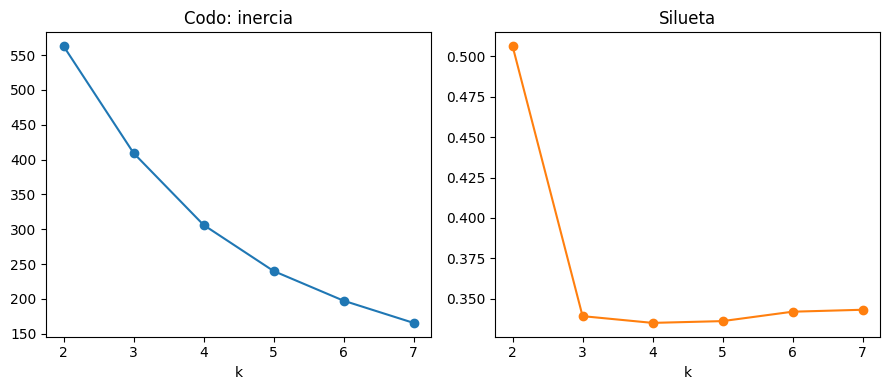

In [57]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

**Interpretación — Gráficos de inercia y silueta**

El gráfico de inercia muestra una reducción progresiva desde 562,8 con K=2 hasta 165,5 con K=7. Sin embargo, esta reducción no permite identificar por sí sola un número óptimo de grupos.

El gráfico de silueta muestra una diferencia más evidente: K=2 alcanza 0,506, mientras que las alternativas entre K=3 y K=7 presentan valores cercanos a 0,34.

En conjunto, los gráficos respaldan la elección de **K=2 cuando se prioriza la separación entre grupos**. La utilización posterior de K=3 corresponde a una decisión descriptiva del laboratorio y debe interpretarse considerando su menor calidad de separación.

La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [58]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

,consumo_medio,variabilidad,punta,razon_nocturna
grupo,,,,
0,0.782,0.339,1.418,0.638
1,1.442,0.626,2.614,0.636
2,2.606,1.131,4.719,0.639



Tamaño de cada grupo:
grupo
0    132
1     98
2     30


### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

**Grupo 0: Bajo consumo y comportamiento relativamente estable.**

Este grupo contiene 132 medidores. Presenta el consumo medio más bajo (0,782), menor variabilidad (0,339) y una punta de consumo de 1,418.

**Grupo 1: Consumo intermedio y variabilidad moderada.**

Este grupo contiene 98 medidores. Registra un consumo medio de 1,442, una variabilidad de 0,626 y una punta de 2,614. Sus valores son superiores a los del grupo 0, pero inferiores a los del grupo 2.

**Grupo 2: Alto consumo y elevada variabilidad.**

Este grupo contiene 30 medidores. Presenta el mayor consumo medio (2,606), la mayor variabilidad (1,131) y la punta más alta (4,719).

En los tres grupos, la razón nocturna es similar, con valores cercanos a 0,64, por lo que las principales diferencias se observan en el nivel y la variabilidad del consumo.

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

In [59]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 97): 2.49
Medidores anómalos: 8 de 260


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,2,4.803
M00074,3.852,1.656,6.983,0.636,2,3.319
M00028,1.002,0.447,1.819,0.610,1,3.187
M00191,3.689,1.606,6.779,0.641,2,2.956
M00041,3.215,1.407,5.848,0.619,2,2.908
M00050,0.744,0.327,1.347,0.614,0,2.864
M00008,0.602,0.262,1.080,0.661,0,2.724
M00097,3.473,1.522,6.326,0.632,2,2.499


**Interpretación — Identificación de medidores anómalos**

Se calculó la distancia de cada uno de los 260 medidores al centroide del grupo asignado mediante K-Means, utilizando las variables estandarizadas.

Se estableció como umbral el percentil 97 de las distancias, equivalente aproximadamente a 2,49. Los medidores que superaron ese valor fueron considerados potencialmente anómalos.

Con este criterio se identificaron 8 medidores, aproximadamente el 3,1 % del total.

El caso más extremo corresponde al medidor M00184, con una distancia de 4,803, seguido por M00074 (3,319) y M00028 (3,187).

Estos resultados permiten priorizar los medidores que requieren una revisión más detallada. Sin embargo, una distancia elevada no demuestra necesariamente que exista un error de medición, ya que también puede representar un comportamiento de consumo real, pero poco habitual.

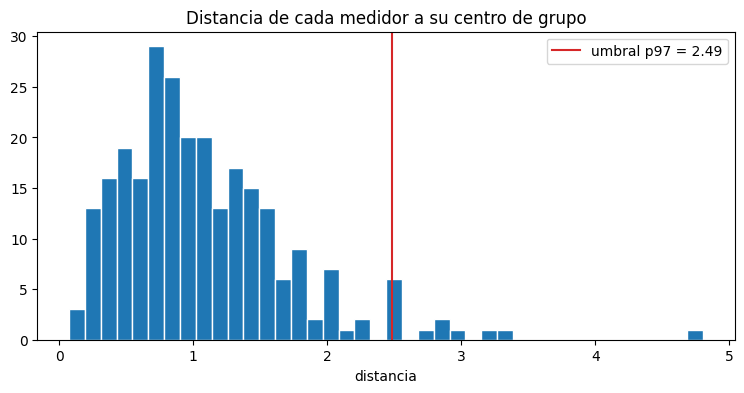

In [60]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

**Interpretación — Distribución de distancias y umbral de anomalías**

El histograma muestra que la mayoría de los medidores presenta distancias relativamente pequeñas respecto del centroide de su grupo, concentrándose principalmente alrededor de valores inferiores a 1,5.

La línea vertical roja representa el umbral del percentil 97, situado aproximadamente en 2,49.

Los medidores ubicados a la derecha de esta línea corresponden a los ocho casos seleccionados para revisión. Destaca un valor extremo cercano a 4,8, considerablemente alejado de la distribución principal.

La elección del percentil 97 permite concentrar el análisis en los casos más alejados de sus grupos. No obstante, este umbral es una decisión metodológica y debe ajustarse según los objetivos del análisis y la capacidad disponible para investigar los casos detectados.

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [61]:
# Actividad 3.1 — Revisar los tres medidores más anómalos

top_3_anomalos = (
    anomalos
    .sort_values('distancia', ascending=False)
    .head(3)
)

print("=== TRES MEDIDORES MÁS ANÓMALOS ===")
display(top_3_anomalos.round(3))

for medidor in top_3_anomalos.index:
    detalle = grande[
        grande['medidor_id'] == medidor
    ].copy()

    print(f"\n=== MEDIDOR {medidor} ===")
    print("Cantidad de mediciones:", len(detalle))
    print("Comuna:", detalle['comuna'].mode().iloc[0])
    print("Tarifa:", detalle['tarifa'].mode().iloc[0])

    print("Consumo mínimo:",
          round(detalle['consumo_kwh'].min(), 3))
    print("Consumo medio:",
          round(detalle['consumo_kwh'].mean(), 3))
    print("Consumo máximo:",
          round(detalle['consumo_kwh'].max(), 3))

    print("\nCinco mediciones de mayor consumo:")
    display(
        detalle.nlargest(5, 'consumo_kwh')[
            ['fecha_hora', 'comuna', 'tarifa',
             'consumo_kwh', 'temperatura_c']
        ]
    )

=== TRES MEDIDORES MÁS ANÓMALOS ===


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,2,4.803
M00074,3.852,1.656,6.983,0.636,2,3.319
M00028,1.002,0.447,1.819,0.610,1,3.187



=== MEDIDOR M00184 ===
Cantidad de mediciones: 1080
Comuna: Los Ángeles
Tarifa: BT2
Consumo mínimo: 1.267
Consumo medio: 4.327
Consumo máximo: 11.628

Cinco mediciones de mayor consumo:


,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c
189724,2025-05-31 18:00:00,Los Ángeles,BT2,11.628,10.4
255504,2025-06-21 20:00:00,Los Ángeles,BT2,11.471,5.8
74544,2025-04-24 20:00:00,Los Ángeles,BT2,10.577,8.5
206884,2025-06-06 06:00:00,Los Ángeles,BT2,10.550,3.8
249264,2025-06-19 20:00:00,Los Ángeles,BT2,10.501,8.4



=== MEDIDOR M00074 ===
Cantidad de mediciones: 1080
Comuna: Talcahuano
Tarifa: BT1
Consumo mínimo: 1.188
Consumo medio: 3.852
Consumo máximo: 11.745

Cinco mediciones de mayor consumo:


,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c
164914,2025-05-23 20:00:00,Talcahuano,BT1,11.745,7.8
71314,2025-04-23 20:00:00,Talcahuano,BT1,9.606,8.6
258514,2025-06-22 20:00:00,Talcahuano,BT1,9.458,7.5
174534,2025-05-26 22:00:00,Talcahuano,BT1,9.354,6.6
267874,2025-06-25 20:00:00,Talcahuano,BT1,9.185,8.3



=== MEDIDOR M00028 ===
Cantidad de mediciones: 1080
Comuna: Talcahuano
Tarifa: BT1
Consumo mínimo: 0.309
Consumo medio: 1.002
Consumo máximo: 2.758

Cinco mediciones de mayor consumo:


,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c
149268,2025-05-18 20:00:00,Talcahuano,BT1,2.758,7.4
136788,2025-05-14 20:00:00,Talcahuano,BT1,2.585,7.4
270948,2025-06-26 20:00:00,Talcahuano,BT1,2.549,7.9
128988,2025-05-12 08:00:00,Talcahuano,BT1,2.466,7.5
7308,2025-04-03 08:00:00,Talcahuano,BT1,2.420,10.9


**Diagnóstico de los tres medidores más anómalos**

Criterio utilizado: Se consideraron anómalos los medidores cuya distancia al centro de su grupo supera el percentil 97 (2,49). Se seleccionó este umbral para concentrar la revisión en aproximadamente el 3 % de los casos más alejados, sin eliminar registros automáticamente.

Medidor M00184 — Posible fenómeno real de alto consumo.

Este medidor pertenece a Los Ángeles y tiene tarifa BT2. Presenta un consumo medio de 4,327 kWh, un máximo de 11,628 kWh y una distancia de 4,803, la más alta del conjunto. Sus mediciones elevadas aparecen en distintas fechas y horarios, lo que sugiere un comportamiento de consumo elevado y no solamente un valor aislado. No se observan valores imposibles en los datos revisados, por lo que podría representar un consumidor de mayor demanda. Sin embargo, sería necesario conocer las características de la instalación para confirmar su causa.

Medidor M00074 — Posible fenómeno real de alto consumo, pendiente de validación.

Este medidor está ubicado en Talcahuano y tiene tarifa BT1. Registra un consumo medio de 3,852 kWh, un máximo de 11,745 kWh y una distancia de 3,319. Sus consumos más altos aparecen en diferentes fechas, principalmente durante la tarde y noche. Aunque estos valores son elevados, no existe evidencia suficiente para clasificarlos como errores de registro. Podrían corresponder a períodos de mayor demanda eléctrica, pero sería recomendable revisar el historial completo y las características del suministro.

Medidor M00028 — Posible fenómeno real de comportamiento horario diferente.

Este medidor también se encuentra en Talcahuano y tiene tarifa BT1. Su consumo medio es de 1,002 kWh y su máximo alcanza 2,758 kWh, valores considerablemente menores que los otros dos casos. Sin embargo, presenta una razón nocturna de 0,610, inferior al promedio general de 0,637. Esto podría explicar parte de su distancia de 3,187 respecto del centro del grupo. Sus mayores consumos aparecen principalmente a las 08:00 y 20:00 horas, lo que sugiere un patrón horario diferente. No se identifican valores imposibles, por lo que no corresponde eliminarlo sin una revisión adicional.

Conclusión general: Los tres medidores presentan comportamientos poco habituales, pero ninguno puede clasificarse como error de registro con la evidencia disponible. M00184 y M00074 destacan por sus elevados niveles de consumo, mientras que M00028 se diferencia principalmente por su razón nocturna. Por lo tanto, corresponde conservar los registros y considerar una investigación adicional antes de tomar decisiones.


### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

In [62]:
mio = pd.read_csv(RUTA + 'S3_Online_Retail_Explorado.csv', sep=';')
print(mio.shape)
mio.head()

(541909, 18)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Country_norm,ImporteLinea,Anio,Mes,AnioMes,TipoOperacion,Tipo_AJUSTE,Tipo_CANCELACION,Tipo_CANTIDAD_NEGATIVA,Tipo_VENTA
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,UNITED KINGDOM,15.30,2010,12,2010-12,VENTA,0,0,0,1
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,UNITED KINGDOM,22.00,2010,12,2010-12,VENTA,0,0,0,1
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1


**Interpretación — Carga del conjunto Online Retail**

Se cargó el conjunto de datos Online Retail, previamente explorado y preparado durante las actividades anteriores del proyecto.

El archivo contiene 541.909 registros y 18 columnas, con información sobre transacciones, productos, cantidades, precios, clientes y fechas.

Para esta actividad se utilizará el código de producto (StockCode) como unidad de análisis, con el objetivo de construir perfiles comerciales, segmentar los productos según su comportamiento y detectar casos atípicos.

Esta elección permite estudiar diferencias entre productos a partir de su actividad comercial acumulada, en lugar de analizar cada línea de transacción de forma independiente.

In [63]:
# Actividad 3.2 — Construcción de perfiles comerciales

datos = mio.copy()

# Asegurar que las variables sean numéricas
for columna in ['Quantity', 'UnitPrice', 'ImporteLinea']:
    datos[columna] = pd.to_numeric(
        datos[columna],
        errors='coerce'
    )

# Conservar productos comerciales y operaciones clasificadas
datos = datos[
    (datos['StockCode'].notna()) &
    (datos['TipoOperacion'].isin([
        'VENTA', 'CANCELACION', 'CANTIDAD_NEGATIVA'
    ]))
].copy()

# Eliminar registros sin métricas numéricas válidas
datos = datos.dropna(
    subset=['Quantity', 'UnitPrice', 'ImporteLinea']
)

# Construir un perfil por producto
perfil_productos = datos.groupby('StockCode').agg(
    importe_total=('ImporteLinea', 'sum'),
    unidades_netas=('Quantity', 'sum'),
    lineas=('InvoiceNo', 'size'),
    precio_mediano=('UnitPrice', 'median')
)

print("=== PERFILES COMERCIALES ===")
print("Registros utilizados:", len(datos))
print("Productos:", len(perfil_productos))
print("Dimensiones:", perfil_productos.shape)

display(perfil_productos.describe().round(2))



# Diagnóstico adicional de códigos especiales

codigos_revisar = [
    'AMAZONFEE',
    'M',
    'CRUK',
    'BANK CHARGES',
    'D',
    'DOT'
]

print("=== DESCRIPCIONES DE CÓDIGOS ESPECIALES ===")

for codigo in codigos_revisar:
    registros = datos[datos['StockCode'] == codigo]

    print(f"\nCódigo: {codigo}")
    print("Registros:", len(registros))

    display(
        registros['Description']
        .value_counts(dropna=False)
        .head(5)
        .to_frame('Frecuencia')
    )


# Diagnóstico previo a k-means

print("=== CALIDAD DE LOS PERFILES ===")
print("Importes negativos:",
      (perfil_productos['importe_total'] < 0).sum())
print("Unidades negativas:",
      (perfil_productos['unidades_netas'] < 0).sum())
print("Precios medianos iguales a cero:",
      (perfil_productos['precio_mediano'] == 0).sum())
print("Productos con una sola línea:",
      (perfil_productos['lineas'] == 1).sum())

print("\n=== CINCO PRODUCTOS CON MAYOR IMPORTE ===")
display(
    perfil_productos.nlargest(
        5, 'importe_total'
    ).round(2)
)

print("\n=== CINCO PRODUCTOS CON MENOR IMPORTE ===")
display(
    perfil_productos.nsmallest(
        5, 'importe_total'
    ).round(2)
)

print("\n=== CINCO PRODUCTOS CON MAYOR PRECIO MEDIANO ===")
display(
    perfil_productos.nlargest(
        5, 'precio_mediano'
    ).round(2)
)


=== PERFILES COMERCIALES ===
Registros utilizados: 541875
Productos: 4068
Dimensiones: (4068, 4)


,importe_total,unidades_netas,lineas,precio_mediano
count,4068.00,4068.00,4068.00,4068.00
mean,2398.92,1272.98,133.20,5.08
std,7930.66,3053.94,199.93,93.19
min,-221520.50,-14418.00,1.00,0.00
25%,95.32,32.00,14.00,0.85
50%,613.16,301.00,62.00,1.95
75%,2089.20,1280.00,167.00,4.13
max,206245.48,56450.00,2313.00,5909.88


=== DESCRIPCIONES DE CÓDIGOS ESPECIALES ===

Código: AMAZONFEE
Registros: 34


,Frecuencia
Description,
AMAZON FEE,34



Código: M
Registros: 571


,Frecuencia
Description,
Manual,571


... (10 outputs left out)


=== CINCO PRODUCTOS CON MENOR IMPORTE ===


,importe_total,unidades_netas,lineas,precio_mediano
StockCode,,,,
AMAZONFEE,-221520.50,-30,34,5909.88
M,-68674.19,3164,571,7.95
CRUK,-7933.43,-16,16,471.77
BANK CHARGES,-7175.64,-13,37,82.73
D,-5696.22,-1194,77,22.97



=== CINCO PRODUCTOS CON MAYOR PRECIO MEDIANO ===


,importe_total,unidades_netas,lineas,precio_mediano
StockCode,,,,
AMAZONFEE,-221520.50,-30,34,5909.88
CRUK,-7933.43,-16,16,471.77
DOT,206245.48,1707,710,184.94
22827,5000.00,28,31,165.00
22828,1530.00,10,7,165.00


**Interpretación — Construcción y diagnóstico de perfiles comerciales**

Se analizaron 541.875 registros válidos del conjunto Online Retail y se construyeron 4.068 perfiles de productos, utilizando `StockCode` como unidad de análisis.

Cada perfil contiene cuatro variables: importe total acumulado, unidades netas, cantidad de líneas de transacción y precio mediano.

El análisis exploratorio identificó valores negativos en importes y cantidades, así como precios iguales a cero y productos con escasa actividad. También se revisaron códigos especiales como `AMAZONFEE`, `M`, `CRUK`, `BANK CHARGES`, `D` y `DOT`, asociados a conceptos administrativos o servicios que no representan productos comerciales convencionales.

Estos resultados justifican aplicar criterios de selección antes de la segmentación, con el propósito de analizar productos con actividad comercial suficiente y métricas válidas.

La exploración permite fundamentar el filtrado posterior sin modificar ni eliminar los registros originales del conjunto de datos.

In [64]:
# Actividad 3.2 — Preparación y estandarización

from sklearn.preprocessing import StandardScaler

# Códigos especiales identificados en el diagnóstico
codigos_especiales = [
    'AMAZONFEE',
    'M',
    'CRUK',
    'BANK CHARGES',
    'D',
    'DOT'
]

# Copia independiente para segmentación
perfil_segmentacion = perfil_productos.loc[
    ~perfil_productos.index.isin(codigos_especiales)
].copy()

# Seleccionar perfiles comerciales con actividad suficiente
perfil_segmentacion = perfil_segmentacion[
    (perfil_segmentacion['lineas'] >= 10) &
    (perfil_segmentacion['importe_total'] > 0) &
    (perfil_segmentacion['unidades_netas'] > 0) &
    (perfil_segmentacion['precio_mediano'] > 0)
].copy()

# Variables utilizadas en la segmentación
variables = [
    'importe_total',
    'unidades_netas',
    'lineas',
    'precio_mediano'
]

# Transformación logarítmica para reducir asimetría
X_log = np.log1p(perfil_segmentacion[variables])

# Estandarización
escalador = StandardScaler()
X_productos = escalador.fit_transform(X_log)

print("=== PREPARACIÓN PARA K-MEANS ===")
print("Perfiles originales:", len(perfil_productos))
print("Perfiles seleccionados:", len(perfil_segmentacion))
print("Perfiles excluidos:",
      len(perfil_productos) - len(perfil_segmentacion))

print("\nMedias estandarizadas:",
      X_productos.mean(axis=0).round(3))
print("Desviaciones estandarizadas:",
      X_productos.std(axis=0).round(3))

print("\n=== RESUMEN DE PERFILES SELECCIONADOS ===")
display(perfil_segmentacion[variables].describe().round(2))

=== PREPARACIÓN PARA K-MEANS ===
Perfiles originales: 4068
Perfiles seleccionados: 3164
Perfiles excluidos: 904

Medias estandarizadas: [-0. -0.  0. -0.]
Desviaciones estandarizadas: [1. 1. 1. 1.]

=== RESUMEN DE PERFILES SELECCIONADOS ===


,importe_total,unidades_netas,lineas,precio_mediano
count,3164.00,3164.00,3164.00,3164.00
mean,3091.91,1654.67,168.72,3.25
std,6938.38,3347.25,212.86,6.13
min,10.61,2.00,10.00,0.04
25%,355.58,167.75,38.00,0.85
50%,1017.44,586.00,98.50,1.95
75%,2916.22,1777.75,213.00,3.75
max,164762.19,56450.00,2313.00,165.00


**Interpretación — Selección y estandarización de productos comerciales**

De los 4.068 perfiles iniciales se seleccionaron 3.164 productos comerciales, excluyendo 904 perfiles que no cumplían los criterios definidos.

Se excluyeron códigos administrativos identificados previamente y se exigió un mínimo de 10 líneas registradas por producto, además de valores positivos en importe total, unidades netas y precio mediano.

Para la segmentación se utilizaron cuatro características: importe total, unidades netas, cantidad de líneas y precio mediano.

Se aplicó una transformación logarítmica mediante np.log1p() para reducir la asimetría de las variables y posteriormente se utilizó StandardScaler() para estandarizarlas.

La estandarización permite que las cuatro variables participen en el cálculo de distancias de K-Means sin que sus diferencias originales de escala dominen la agrupación.

Los perfiles excluidos se conservaron en el conjunto original, evitando su eliminación definitiva.

=== COMPARACIÓN DE GRUPOS — ONLINE RETAIL ===


,k,silueta,inercia,tamanos
0,2,0.393,6875.518,"[1380, 1784]"
1,3,0.315,5266.787,"[905, 1056, 1203]"
2,4,0.343,3906.905,"[749, 751, 1078, 586]"
3,5,0.327,3339.926,"[619, 485, 1033, 567, 460]"
4,6,0.311,2828.173,"[454, 709, 747, 350, 426, 478]"
5,7,0.318,2502.960,"[215, 507, 415, 451, 368, 749, 459]"


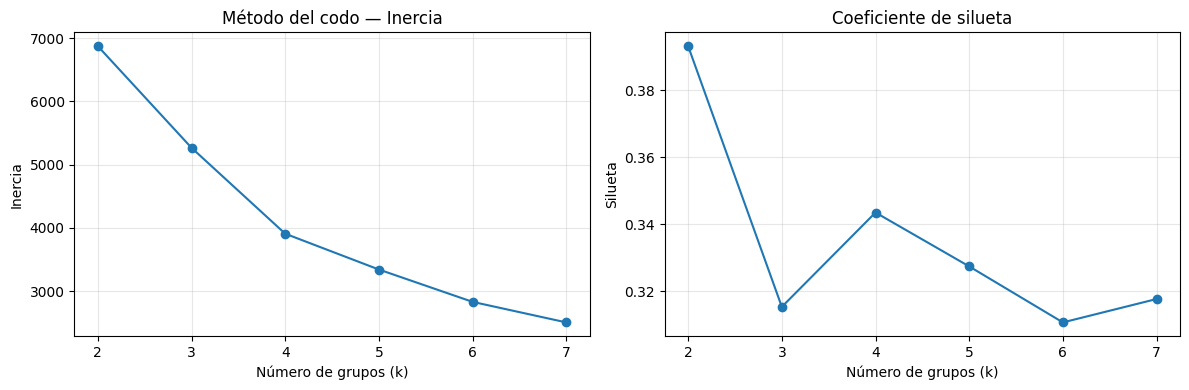


Mejor k según silueta: 2


In [65]:
# Actividad 3.2 — Comparación de valores de k

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_productos = []

for k in range(2, 8):

    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_productos)

    silueta = silhouette_score(
        X_productos,
        etiquetas,
        sample_size=min(2000, len(X_productos)),
        random_state=SEMILLA
    )

    resultados_productos.append({
        'k': k,
        'silueta': silueta,
        'inercia': modelo.inertia_,
        'tamanos': np.bincount(etiquetas).tolist()
    })

resultados_k = pd.DataFrame(resultados_productos)

print("=== COMPARACIÓN DE GRUPOS — ONLINE RETAIL ===")
display(resultados_k.round(3))

# Gráficos de silueta e inercia
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(
    resultados_k['k'],
    resultados_k['inercia'],
    'o-'
)
ax[0].set_title('Método del codo — Inercia')
ax[0].set_xlabel('Número de grupos (k)')
ax[0].set_ylabel('Inercia')
ax[0].grid(alpha=0.3)

ax[1].plot(
    resultados_k['k'],
    resultados_k['silueta'],
    'o-'
)
ax[1].set_title('Coeficiente de silueta')
ax[1].set_xlabel('Número de grupos (k)')
ax[1].set_ylabel('Silueta')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nMejor k según silueta:",
      int(resultados_k.loc[
          resultados_k['silueta'].idxmax(), 'k'
      ]))

**Interpretación — Selección del número de grupos en Online Retail**

Se compararon seis alternativas de segmentación, desde K=2 hasta K=7, utilizando el coeficiente de silueta y la inercia.

El mayor coeficiente de silueta se obtuvo con K=2, alcanzando un valor de 0,393. La alternativa K=4 obtuvo 0,343, mientras que los demás valores de K presentaron resultados inferiores al de K=2.

Estos resultados indican que la división en dos grupos presenta la mejor separación relativa entre las alternativas evaluadas. Sin embargo, el valor de silueta obtenido refleja una separación moderada, por lo que los grupos no deben considerarse completamente diferenciados.

Por otra parte, la inercia permite observar cómo disminuye la dispersión interna al aumentar la cantidad de grupos, pero no constituye por sí sola una justificación suficiente para seleccionar K.

**Conclusión:** Se seleccionó K=2 porque presenta la mejor silueta entre los valores evaluados. La segmentación será utilizada con fines exploratorios y sus resultados deberán validarse antes de respaldar decisiones comerciales.

In [66]:
# Actividad 3.2 — Caracterización de grupos comerciales

# Modelo definitivo con k=2
modelo_final = KMeans(
    n_clusters=2,
    random_state=SEMILLA,
    n_init=10
)

etiquetas_finales = modelo_final.fit_predict(X_productos)

# Asociar cada producto a su grupo
perfil_segmentacion['grupo'] = etiquetas_finales

# Cantidad de productos por grupo
tamanos = (
    perfil_segmentacion['grupo']
    .value_counts()
    .sort_index()
)

# Estadísticas comerciales por grupo
resumen_grupos = perfil_segmentacion.groupby('grupo')[
    variables
].agg(['mean', 'median']).round(2)

print("=== TAMAÑO DE LOS GRUPOS ===")
display(tamanos.to_frame('Productos'))

print("\n=== CARACTERIZACIÓN DE GRUPOS ===")
display(resumen_grupos)

print("\n=== CINCO PRODUCTOS CON MAYOR IMPORTE POR GRUPO ===")

for grupo in sorted(perfil_segmentacion['grupo'].unique()):
    print(f"\nGrupo {grupo}")
    display(
        perfil_segmentacion[
            perfil_segmentacion['grupo'] == grupo
        ].nlargest(5, 'importe_total')[
            variables
        ].round(2)
    )

=== TAMAÑO DE LOS GRUPOS ===


,Productos
grupo,
0,1380
1,1784



=== CARACTERIZACIÓN DE GRUPOS ===


importe_total          unidades_netas          lineas         \
               mean   median           mean  median    mean median   
grupo                                                                
0            464.55   298.21         196.18   132.5   40.00   34.0   
1           5124.28  2403.72        2782.88  1527.0  268.29  190.0   

      precio_mediano         
                mean median  
grupo                        
0               4.08   2.51  
1               2.61   1.65


=== CINCO PRODUCTOS CON MAYOR IMPORTE POR GRUPO ===

Grupo 0


,importe_total,unidades_netas,lineas,precio_mediano
StockCode,,,,
22655,6394.50,39,47,125.00
22783,5961.25,465,34,14.72
22826,5692.50,54,45,85.00
22827,5000.00,28,31,165.00
22504,4542.07,242,72,16.63



Grupo 1


,importe_total,unidades_netas,lineas,precio_mediano
StockCode,,,,
22423,164762.19,12980,2203,12.75
47566,98302.98,18022,1727,4.95
85123A,97894.50,38830,2313,2.95
85099B,92356.03,47363,2159,2.08
23084,66756.59,31130,1066,2.08


**Caracterización de los grupos comerciales**

Se seleccionaron 3.164 productos comerciales para la segmentación, utilizando cuatro atributos: importe total, unidades netas, cantidad de líneas y precio mediano. Las variables se transformaron mediante logaritmos y posteriormente se estandarizaron.

Se compararon seis valores de k, desde 2 hasta 7. Se seleccionó k=2 porque obtuvo el mayor coeficiente de silueta (0,393), aunque este valor indica una separación moderada y no una división completamente definida.

Grupo 0 — Productos de baja rotación y menor importe acumulado: contiene 1.380 productos. Registra un importe medio de 464,55, una media de 196,18 unidades netas y aproximadamente 40 líneas por producto. Su precio mediano promedio es de 4,08. Estos resultados describen productos de menor actividad comercial dentro del conjunto analizado.

Grupo 1 — Productos de alta rotación y mayor importe acumulado: contiene 1.784 productos. Presenta un importe medio de 5.124,28, una media de 2.782,88 unidades netas y aproximadamente 268 líneas por producto. Su precio mediano promedio es de 2,61. Estos productos concentran una actividad comercial considerablemente mayor.

En conclusión, la segmentación permite distinguir productos de mayor y menor actividad comercial. Esta clasificación podría servir para orientar análisis de inventario, promociones y seguimiento de ventas, pero debe validarse antes de utilizarla para tomar decisiones comerciales.

=== ANOMALÍAS COMERCIALES — ONLINE RETAIL ===
Productos analizados: 3164
Umbral percentil 97: 2.617
Productos anómalos: 95

=== DIEZ PRODUCTOS MÁS ANÓMALOS ===


,importe_total,unidades_netas,lineas,precio_mediano,grupo,distancia
StockCode,,,,,,
22827,5000.00,28,31,165.00,0,6.22
22655,6394.50,39,47,125.00,0,5.86
22656,2885.00,18,27,125.00,0,5.77
22823,2745.00,24,15,110.00,0,5.58
22826,5692.50,54,45,85.00,0,5.26
22929,1004.75,16,15,65.00,0,4.73
C2,6986.00,290,144,50.00,1,4.59
22423,164762.19,12980,2203,12.75,1,4.33
84078A,15115.05,380,163,39.95,1,4.32


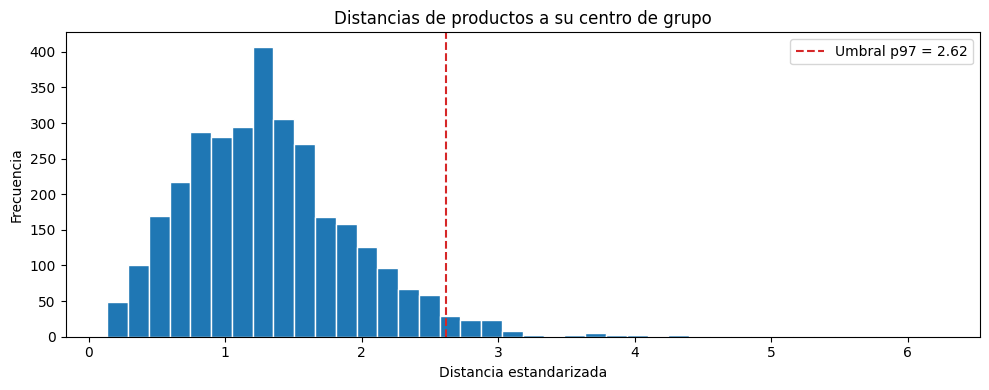

In [67]:
# Actividad 3.2 — Detección de anomalías comerciales

# Calcular distancia de cada producto a su centro
distancias_productos = np.linalg.norm(
    X_productos -
    modelo_final.cluster_centers_[etiquetas_finales],
    axis=1
)

# Agregar las distancias a los perfiles
perfil_segmentacion['distancia'] = distancias_productos

# Umbral de anomalía: percentil 97
umbral_productos = np.percentile(
    distancias_productos, 97
)

# Seleccionar anomalías
anomalias_productos = perfil_segmentacion[
    perfil_segmentacion['distancia'] > umbral_productos
].copy()

anomalias_productos = anomalias_productos.sort_values(
    'distancia',
    ascending=False
)

print("=== ANOMALÍAS COMERCIALES — ONLINE RETAIL ===")
print("Productos analizados:", len(perfil_segmentacion))
print("Umbral percentil 97:", round(umbral_productos, 3))
print("Productos anómalos:", len(anomalias_productos))

print("\n=== DIEZ PRODUCTOS MÁS ANÓMALOS ===")
display(
    anomalias_productos.head(10).round(2)
)

# Histograma de distancias
plt.figure(figsize=(10, 4))

plt.hist(
    distancias_productos,
    bins=40,
    edgecolor='white'
)

plt.axvline(
    umbral_productos,
    color='C3',
    linestyle='--',
    label=f'Umbral p97 = {umbral_productos:.2f}'
)

plt.title('Distancias de productos a su centro de grupo')
plt.xlabel('Distancia estandarizada')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación — Detección de anomalías comerciales**

Se calcularon las distancias de los 3.164 productos comerciales respecto del centroide de su grupo, utilizando las variables transformadas y estandarizadas.

Se estableció como criterio de anomalía el percentil 97 de las distancias, obteniendo un umbral de 2,617. Con este procedimiento se identificaron 95 productos potencialmente atípicos, equivalentes aproximadamente al 3 % del conjunto analizado.

El histograma permite distinguir la concentración principal de productos y aquellos que presentan distancias superiores al umbral establecido.

Estas anomalías representan productos con características comerciales poco habituales respecto de su grupo, pero no necesariamente errores en los datos. Podrían corresponder a productos de mayor precio, menor frecuencia de venta u otros comportamientos comerciales particulares.

Por lo tanto, los casos identificados deben examinarse individualmente antes de considerar modificaciones o exclusiones del conjunto de datos.

In [68]:
# Actividad 3.2 — Investigación de los tres productos más anómalos

codigos_anomalos = (
    anomalias_productos
    .head(3)
    .index
    .tolist()
)

print("=== TRES PRODUCTOS MÁS ANÓMALOS ===")
print(codigos_anomalos)

for codigo in codigos_anomalos:

    detalle = datos[
        datos['StockCode'] == codigo
    ].copy()

    print(f"\n=== PRODUCTO {codigo} ===")
    print("Registros:", len(detalle))

    print("\nDescripciones:")
    display(
        detalle['Description']
        .value_counts(dropna=False)
        .head(5)
        .to_frame('Frecuencia')
    )

    print("\nEstadísticas de cantidades y precios:")
    display(
        detalle[
            ['Quantity', 'UnitPrice', 'ImporteLinea']
        ].describe().round(2)
    )

    print("\nTipos de operación:")
    display(
        detalle['TipoOperacion']
        .value_counts(dropna=False)
        .to_frame('Frecuencia')
    )

    print("\nCinco registros de mayor importe:")
    display(
        detalle.nlargest(5, 'ImporteLinea')[
            ['InvoiceNo', 'InvoiceDate', 'Description',
             'Quantity', 'UnitPrice', 'ImporteLinea',
             'TipoOperacion']
        ]
    )

=== TRES PRODUCTOS MÁS ANÓMALOS ===
['22827', '22655', '22656']

=== PRODUCTO 22827 ===
Registros: 31

Descripciones:


,Frecuencia
Description,
RUSTIC SEVENTEEN DRAWER SIDEBOARD,29
NaN,2



Estadísticas de cantidades y precios:


,Quantity,UnitPrice,ImporteLinea
count,31.00,31.00,31.00
mean,0.90,145.97,161.29
std,1.92,42.12,125.82
min,-8.00,0.00,-165.00
25%,1.00,145.00,165.00
50%,1.00,165.00,165.00
75%,2.00,165.00,290.00
max,4.00,165.00,290.00



Tipos de operación:


,Frecuencia
TipoOperacion,
VENTA,27
CANCELACION,3
CANTIDAD_NEGATIVA,1


... (14 outputs left out)


Tipos de operación:


,Frecuencia
TipoOperacion,
VENTA,20
CANCELACION,6
CANTIDAD_NEGATIVA,1



Cinco registros de mayor importe:


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,ImporteLinea,TipoOperacion
118769,546480,2011-03-14 11:38:00,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,VENTA
133994,547814,2011-03-25 14:19:00,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,VENTA
171178,551393,2011-04-28 12:22:00,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0,VENTA
28902,538662,2010-12-13 15:44:00,VINTAGE BLUE KITCHEN CABINET,2,125.0,250.0,VENTA
31614,538999,2010-12-15 12:09:00,VINTAGE BLUE KITCHEN CABINET,2,125.0,250.0,VENTA


### Interpretación de la segmentación y detección de anomalías — Online Retail

**1. Preparación y unidad de análisis**

Se utilizó como unidad de análisis cada producto identificado mediante StockCode. Inicialmente se construyeron 4.068 perfiles comerciales, considerando importe neto acumulado, unidades netas, cantidad de líneas registradas y precio mediano.

Para la segmentación se seleccionaron 3.164 productos, excluyendo 904 perfiles que no cumplían los criterios establecidos. Entre estos criterios se consideraron los códigos administrativos identificados, un mínimo de 10 líneas y valores positivos en las métricas comerciales seleccionadas.

Las variables se transformaron mediante logaritmos y posteriormente se estandarizaron para reducir las diferencias de escala y la influencia de valores extremos.

**2. Selección del número de grupos**

Se evaluaron seis alternativas, desde k=2 hasta k=7, utilizando la inercia y el coeficiente de silueta.

Se seleccionó k=2 porque obtuvo la mayor silueta (0,393), frente a 0,343 para k=4 y valores inferiores para las demás alternativas. Este resultado indica una separación moderada, por lo que los grupos deben interpretarse como una aproximación exploratoria.

**3. Caracterización de los grupos**

**Grupo 0 — Productos de menor actividad comercial:** contiene 1.380 productos. Presenta un importe medio acumulado de 464,55, una media de 196,18 unidades netas y aproximadamente 40 líneas por producto. Su precio mediano promedio es de 4,08.

**Grupo 1 — Productos de mayor actividad comercial:** contiene 1.784 productos. Registra un importe medio acumulado de 5.124,28, una media de 2.782,88 unidades netas y aproximadamente 268 líneas por producto. Su precio mediano promedio es de 2,61.

Los resultados muestran que los productos del segundo grupo presentan mayor volumen de actividad e importes acumulados, aunque sus precios unitarios tienden a ser menores.

**4. Detección de anomalías**

Se calcularon las distancias de cada producto al centro de su grupo y se utilizó el percentil 97 como umbral, obteniendo un valor de 2,617.

Con este criterio se identificaron 95 productos anómalos entre los 3.164 analizados. Los tres casos más extremos fueron:

- **Producto 22827 — RUSTIC SEVENTEEN DRAWER SIDEBOARD:** presenta una distancia de 6,22, un precio mediano de 165,00 y 31 registros. Corresponde a un mueble de mayor valor, con 27 ventas, tres cancelaciones y una operación de cantidad negativa. Sus precios elevados pueden corresponder a un fenómeno comercial real, aunque existen dos registros sin descripción.

- **Producto 22655 — VINTAGE RED KITCHEN CABINET:** presenta una distancia de 5,86, un precio mediano de 125,00 y 47 registros. Se identificaron 38 ventas, ocho cancelaciones y una operación con cantidad negativa. Los precios registrados incluyen valores de 125,00 y 295,00. Esta diferencia requiere revisión, pero no permite concluir que exista un error.

- **Producto 22656 — VINTAGE BLUE KITCHEN CABINET:** presenta una distancia de 5,77, un precio mediano de 125,00 y 27 registros. Se identificaron 20 ventas, seis cancelaciones y una cantidad negativa. También presenta precios de 125,00 y 295,00 y una descripción faltante. Su comportamiento podría corresponder a un artículo de mayor valor y menor frecuencia de venta.

**5. Conclusión general**

La segmentación permitió distinguir dos grupos de productos según su nivel de actividad comercial e importe acumulado.

Las anomalías detectadas corresponden principalmente a productos de precio elevado que presentan una actividad comercial menor que los productos más frecuentes. Los tres casos revisados son compatibles con fenómenos comerciales reales, pero la información disponible no permite descartar completamente errores de registro.

Por esta razón, se conservaron los datos originales y se documentaron las observaciones encontradas, sin eliminar automáticamente los valores extremos.

Como limitación, las conclusiones de esta segmentación corresponden únicamente a los 3.164 productos seleccionados. Además, sería necesario comprobar la estabilidad de los grupos y de las anomalías antes de utilizarlos para tomar decisiones comerciales.



---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

In [69]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor

def comparar(y, columnas, titulo):
    Xv = perfil[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar(perfil['punta'],
         ['consumo_medio', 'variabilidad', 'razon_nocturna'],
         'A · Predecir la PUNTA de consumo')
comparar(perfil['razon_nocturna'],
         ['consumo_medio', 'variabilidad', 'punta'],
         'B · Predecir la RAZÓN NOCTURNA')

A · Predecir la PUNTA de consumo
 profundidad   R² train    R² test
           2      0.892      0.853
           4      0.994      0.984
           8      1.000      0.997
          16      1.000      0.992
        None      1.000      0.992

B · Predecir la RAZÓN NOCTURNA
 profundidad   R² train    R² test
           2      0.060     -0.078
           4      0.182     -0.070
           8      0.569     -0.280
          16      0.970     -0.890
        None      1.000     -0.919



### Lo que muestran las dos tablas

**Caso A — hay relación.** El R² de entrenamiento sube a 1,00 y el de prueba lo acompaña, quedándose en torno a 0,99. El modelo aprendió algo que también vale fuera de los datos con que aprendió.

**Caso B — no hay relación.** Mira la columna de la derecha: el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,9 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a **1,000**: perfecto.

> **Un R² negativo significa que el modelo predice peor que decir siempre el promedio.** Y aun así, sobre los datos de entrenamiento acierta todo. Eso es exactamente el sobreajuste: el árbol no encontró un patrón, **memorizó las filas**.

La lección práctica: si alguien te presenta un modelo con 98 % de acierto y no te dice sobre qué datos se midió, la cifra no significa nada. Un modelo siempre puede memorizar sus propios datos.

**Interpretación — Comparación de modelos y capacidad de generalización**

Se evaluaron dos problemas de predicción utilizando árboles de decisión con diferentes profundidades y una división del conjunto de datos en entrenamiento (70 %) y prueba (30 %).

En el caso A, cuyo objetivo es predecir el consumo de punta, los resultados muestran una relación predictiva fuerte entre las variables. Con una profundidad de 8, el modelo obtuvo un R² de entrenamiento de 1,000 y un R² de prueba de 0,997, indicando un buen desempeño sobre datos no utilizados durante el entrenamiento.

En el caso B, cuyo objetivo es predecir la razón nocturna, todos los valores de R² de prueba fueron negativos. El resultado menos desfavorable fue −0,070 con profundidad 4, mientras que el árbol sin límite de profundidad alcanzó un R² de entrenamiento de 1,000 y uno de prueba de −0,919.

Esta diferencia evidencia sobreajuste en los modelos más complejos del caso B: consiguen ajustarse a los datos de entrenamiento, pero no generalizan adecuadamente.

**Conclusión:** un resultado elevado durante el entrenamiento no garantiza que un modelo sea confiable. Es indispensable evaluar su desempeño sobre datos independientes y utilizar métricas de validación antes de aceptar sus predicciones.

### 4.2 Validación cruzada

Una sola partición puede tocarte fácil o difícil por azar. La validación cruzada parte los datos en k pliegues, entrena k veces y promedia. Lo valioso no es solo la media: es la **desviación**, que dice cuán estable es el resultado.

In [70]:
for etiqueta, y, cols in [
    ('A · punta         ', perfil['punta'],          ['consumo_medio', 'variabilidad', 'razon_nocturna']),
    ('B · razón nocturna', perfil['razon_nocturna'], ['consumo_medio', 'variabilidad', 'punta']),
]:
    for prof in (2, None):
        s = cross_val_score(DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA),
                            perfil[cols], y, cv=5, scoring='r2')
        print(f'{etiqueta}  prof={str(prof):>4s}  R² = {s.mean():7.3f} ± {s.std():.3f}   '
              f'pliegues {np.round(s, 2)}')

A · punta           prof=   2  R² =   0.849 ± 0.019   pliegues [0.82 0.87 0.87 0.83 0.85]
A · punta           prof=None  R² =   0.994 ± 0.003   pliegues [1.   1.   0.99 0.99 0.99]
B · razón nocturna  prof=   2  R² =  -0.104 ± 0.056   pliegues [-0.08 -0.19 -0.03 -0.07 -0.15]
B · razón nocturna  prof=None  R² =  -0.830 ± 0.250   pliegues [-0.35 -0.95 -0.9  -1.08 -0.86]


Dos lecturas:

- El caso A con profundidad ilimitada entrega **0,994 ± 0,003**: estable en los cinco pliegues.
- El caso B con profundidad ilimitada entrega algo como **−0,83 ± 0,25**. No solo es malo: es **inestable**. Según qué pliegue te toque, el resultado cambia mucho.

> **Reporta siempre media y desviación.** Un 0,80 ± 0,03 y un 0,80 ± 0,25 son resultados muy distintos, y el segundo no sostiene ninguna decisión.

**Interpretación — Validación cruzada de los modelos predictivos**

Se aplicó validación cruzada de cinco pliegues para comprobar si los resultados de los modelos se mantienen al utilizar diferentes particiones de los datos.

En el caso A, correspondiente a la predicción del consumo de punta, el árbol sin límite de profundidad obtuvo un R² promedio de 0,994 con una desviación estándar de 0,003. Este resultado indica un desempeño predictivo elevado y estable entre los cinco pliegues.

En el caso B, correspondiente a la predicción de la razón nocturna, el árbol sin límite de profundidad obtuvo un R² promedio de −0,830 con una desviación estándar de 0,250. Estos resultados muestran que el modelo presenta un desempeño deficiente y una variabilidad considerable entre las particiones.

La comparación demuestra que no basta con evaluar el rendimiento de un modelo en una única división de entrenamiento y prueba. También es necesario medir la estabilidad de sus resultados.

**Conclusión:** la validación cruzada respalda la capacidad predictiva del modelo A, mientras que el modelo B no ofrece evidencia suficiente de generalización para utilizar sus predicciones en decisiones prácticas.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

In [71]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\..*"
)

siluetas = []
for i in range(20):
    idx = np.random.RandomState(SEMILLA + i).choice(len(X), int(len(X) * 0.8), replace=False)
    km_i = KMeans(n_clusters=3, random_state=SEMILLA + i, n_init=10).fit(X[idx])
    siluetas.append(silhouette_score(X[idx], km_i.labels_))

siluetas = np.array(siluetas)
print(f'Silueta sobre 20 submuestras del 80 %: {siluetas.mean():.3f} ± {siluetas.std():.3f}')
print(f'Rango: [{siluetas.min():.3f}, {siluetas.max():.3f}]')

Silueta sobre 20 submuestras del 80 %: 0.348 ± 0.018
Rango: [0.323, 0.380]


**Interpretación — Estabilidad de la segmentación de medidores**

Se evaluó la estabilidad de la segmentación K-Means con K=3 utilizando 20 submuestras aleatorias, cada una equivalente al 80 % de los 260 medidores originales.

El coeficiente de silueta promedio fue de 0,348, con una desviación estándar de 0,018. Los valores individuales se situaron entre 0,323 y 0,380.

La desviación relativamente pequeña indica que la calidad de separación de los grupos se mantiene bastante estable al modificar la muestra analizada.

Sin embargo, el valor promedio de silueta refleja una separación limitada entre los tres grupos, por lo que la estabilidad del resultado no implica necesariamente que la segmentación tenga una calidad elevada.

**Conclusión:** la segmentación con K=3 presenta una estabilidad razonable frente a cambios en la muestra, pero sus grupos deben interpretarse con precaución debido a su separación moderada-baja.

### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

=== VALIDACIÓN DE SEGMENTACIÓN ONLINE RETAIL ===
Productos originales: 3164
Submuestras: 20
Porcentaje por submuestra: 80 %
Grupos utilizados: 2

Silueta media: 0.390
Desviación estándar: 0.004
Resultado: 0.390 ± 0.004
Rango: 0.384 a 0.399


,Repeticion,Silueta,Tamanos
0,1,0.390,"[1128, 1403]"
1,2,0.392,"[1438, 1093]"
2,3,0.394,"[1428, 1103]"
3,4,0.390,"[1432, 1099]"
4,5,0.392,"[1417, 1114]"
5,6,0.399,"[1120, 1411]"
6,7,0.384,"[1098, 1433]"
7,8,0.389,"[1411, 1120]"
8,9,0.399,"[1100, 1431]"
9,10,0.386,"[1125, 1406]"


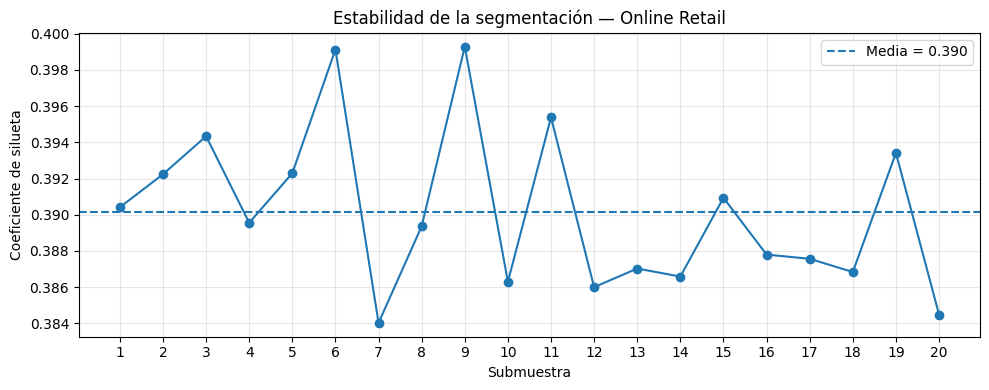

In [72]:
# Actividad 4.1 — Validación de nuestro hallazgo
# Online Retail: estabilidad de la segmentación

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

siluetas_validacion = []
tamanos_validacion = []

# Repetir el análisis sobre 20 submuestras del 80 %
for i in range(20):

    # Seleccionar muestra reproducible
    rng = np.random.RandomState(SEMILLA + i)

    indices = rng.choice(
        len(X_productos),
        size=int(len(X_productos) * 0.8),
        replace=False
    )

    X_muestra = X_productos[indices]

    # Aplicar nuevamente k-means con k=2
    modelo = KMeans(
        n_clusters=2,
        random_state=SEMILLA,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_muestra)

    # Calcular silueta de la submuestra
    silueta = silhouette_score(
        X_muestra,
        etiquetas,
        sample_size=min(1500, len(X_muestra)),
        random_state=SEMILLA + i
    )

    siluetas_validacion.append(silueta)
    tamanos_validacion.append(
        np.bincount(etiquetas).tolist()
    )

# Estadísticas de estabilidad
siluetas_validacion = np.array(siluetas_validacion)

media = siluetas_validacion.mean()
desviacion = siluetas_validacion.std()

print("=== VALIDACIÓN DE SEGMENTACIÓN ONLINE RETAIL ===")
print("Productos originales:", len(X_productos))
print("Submuestras:", len(siluetas_validacion))
print("Porcentaje por submuestra: 80 %")
print("Grupos utilizados: 2")

print(f"\nSilueta media: {media:.3f}")
print(f"Desviación estándar: {desviacion:.3f}")

print(
    f"Resultado: {media:.3f} ± {desviacion:.3f}"
)

print(
    f"Rango: {siluetas_validacion.min():.3f} "
    f"a {siluetas_validacion.max():.3f}"
)

# Mostrar resultados por repetición
resultados_validacion = pd.DataFrame({
    'Repeticion': range(1, 21),
    'Silueta': siluetas_validacion,
    'Tamanos': tamanos_validacion
})

display(resultados_validacion.round(3))

# Gráfico de estabilidad
plt.figure(figsize=(10, 4))

plt.plot(
    resultados_validacion['Repeticion'],
    resultados_validacion['Silueta'],
    marker='o'
)

plt.axhline(
    media,
    linestyle='--',
    label=f'Media = {media:.3f}'
)

plt.title('Estabilidad de la segmentación — Online Retail')
plt.xlabel('Submuestra')
plt.ylabel('Coeficiente de silueta')
plt.xticks(range(1, 21))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Validación de robustez de la segmentación — Online Retail**

**Hallazgo evaluado:** La segmentación de Online Retail permite distinguir dos grupos de productos según su nivel de actividad comercial e importe acumulado.

Para comprobar la robustez del hallazgo, se realizaron 20 repeticiones de k-means con k=2, utilizando submuestras aleatorias del 80 % de los 3.164 productos seleccionados. Se mantuvo la semilla del laboratorio para asegurar la reproducibilidad.

La segmentación original obtuvo una silueta estimada de 0,393. En las 20 submuestras, la silueta media fue de **0,390 ± 0,004**, con valores entre 0,384 y 0,399.

Estos resultados muestran que la calidad de separación se mantiene relativamente estable al utilizar diferentes submuestras. La desviación estándar es pequeña y los valores obtenidos son cercanos al resultado original.

Sin embargo, una silueta de aproximadamente 0,39 indica una separación moderada, por lo que los grupos no representan categorías completamente diferenciadas. Además, esta validación evalúa principalmente la estabilidad del coeficiente de silueta y no garantiza que cada producto mantenga exactamente su clasificación.

**Conclusión:** Considero que el hallazgo es consistente como resultado exploratorio y permite formular una hipótesis sobre la existencia de productos de mayor y menor actividad comercial. Puede utilizarse para orientar análisis posteriores, pero todavía no constituye evidencia suficiente para tomar decisiones comerciales definitivas.

Antes de utilizar esta segmentación para definir políticas de inventario o promociones, sería recomendable comprobar su estabilidad con otros períodos, criterios de preparación y asignaciones individuales de productos.



---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [73]:
import os, time

ruta = 'S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

Tamaño en disco: 13.2 MB


### Estrategia A · leer todo

In [74]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Tiempo: 0.25 s · Memoria: 68.0 MB · Filas: 280,800


Fíjate: **13 MB en disco se convierten en unos 78 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

### Estrategia B · leer solo las columnas necesarias

In [75]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

Tiempo: 0.19 s · Memoria: 16.9 MB
Reducción de memoria: 75 %


**Interpretación — Estrategia B: Lectura de columnas seleccionadas**

La estrategia B consistió en cargar únicamente las columnas `medidor_id` y `consumo_kwh`, en lugar de leer todas las variables del archivo.

El tiempo de ejecución fue de 0,20 segundos y el consumo de memoria alcanzó 16,9 MB, frente a los 68,0 MB utilizados por la estrategia A.

Esto representa una reducción aproximada del 75 % en el consumo de memoria, manteniendo los datos necesarios para calcular los agregados de consumo por medidor.

La reducción se obtiene porque se evita almacenar información que no será utilizada en el análisis.

**Conclusión:** seleccionar únicamente las columnas necesarias constituye una optimización sencilla y efectiva para reducir el uso de memoria sin alterar la información requerida para el procesamiento.

### Estrategia C · procesar por bloques

In [76]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

Tiempo: 0.28 s · Memoria máxima: la de UN bloque, no la del archivo
Medidores agregados: 260


**Interpretación — Estrategia C: Procesamiento por bloques**

La estrategia C procesó el archivo mediante bloques de 50.000 registros, utilizando el parámetro `chunksize` de Pandas.

En cada bloque se calcularon las sumas y los conteos de consumo por medidor. Posteriormente, estos resultados parciales se combinaron para obtener los agregados correspondientes a los 260 medidores.

El tiempo de ejecución fue de 0,28 segundos, ligeramente superior a los 0,24 segundos de la estrategia A y los 0,20 segundos de la estrategia B.

Aunque no se midió directamente el consumo máximo de memoria de esta estrategia, el procesamiento por bloques evita cargar simultáneamente el archivo completo. En esta implementación, también se almacenan resultados parciales, por lo que no puede afirmarse un ahorro de memoria específico sin una medición adicional.

La comprobación posterior confirmó que las sumas y los conteos por medidor coinciden con los obtenidos al procesar el archivo completo.

**Conclusión:** el procesamiento por bloques no fue la alternativa más rápida en este ejercicio, pero constituye una estrategia útil para trabajar con conjuntos de datos que no caben completamente en la memoria disponible.

In [77]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

¿Mismo resultado? True


**Interpretación — Comprobación de resultados entre procesamiento completo y por bloques**

Se compararon las sumas de consumo por medidor obtenidas mediante dos procedimientos: la lectura completa del archivo y el procesamiento por bloques.

La comprobación devolvió True, confirmando que las sumas calculadas por ambos métodos son equivalentes dentro de la tolerancia numérica utilizada por np.allclose().

Este resultado demuestra que, para la operación evaluada, el procesamiento por bloques conserva la precisión de los agregados y permite obtener resultados consistentes sin cargar todas las filas del archivo simultáneamente.

La comprobación adicional que aparece a continuación amplía esta validación, comparando también las columnas seleccionadas y los conteos por medidor.

In [78]:
# Comprobación obligatoria — Equivalencia entre estrategias

# Estrategia A vs B: mismos datos en columnas seleccionadas
columnas = ['medidor_id', 'consumo_kwh']

iguales_ab = (
    completo[columnas]
    .reset_index(drop=True)
    .equals(liviano.reset_index(drop=True))
)

# Estrategia A vs C: mismas sumas y conteos por medidor
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(
    ['sum', 'count']
)

a = directo.sort_index()
c = por_bloques.sort_index()

iguales_ac = (
    a.index.equals(c.index)
    and np.allclose(a['sum'], c['sum'], equal_nan=True)
    and a['count'].equals(c['count'])
)

print("=== VERIFICACIÓN DE ESTRATEGIAS ===")
print("A vs B - Mismos datos:", iguales_ab)
print("A vs C - Mismas sumas y conteos:", iguales_ac)

=== VERIFICACIÓN DE ESTRATEGIAS ===
A vs B - Mismos datos: True
A vs C - Mismas sumas y conteos: True


**Interpretación — Verificación de equivalencia entre estrategias**

La comparación confirmó que las tres estrategias de procesamiento conservan resultados equivalentes para las operaciones evaluadas.

La estrategia A carga todas las columnas, mientras que la estrategia B carga únicamente las necesarias. La comparación entre ambas devolvió True, confirmando que los valores de las columnas seleccionadas coinciden.

La estrategia C procesa el archivo por bloques de 50.000 registros. Al comparar sus sumas y conteos por medidor con los obtenidos mediante la estrategia A, también se obtuvo True.

En cuanto al costo computacional, la estrategia B redujo el consumo de memoria de 68,0 MB a 16,9 MB, equivalente a un ahorro del 75 %. Los tiempos de la última ejecución fueron 0,24 segundos para A, 0,20 segundos para B y 0,28 segundos para C.

**Conclusión:** La selección de columnas mejora la eficiencia de memoria sin alterar los datos necesarios, mientras que el procesamiento por bloques permite trabajar con volúmenes mayores conservando los resultados agregados. En este ejercicio, el procesamiento por bloques no fue la alternativa más rápida, pero ofrece ventajas cuando los archivos superan la memoria disponible.

### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [79]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

A · todo el archivo :  0.25 s ·   68.0 MB
B · dos columnas    :  0.19 s ·   16.9 MB
C · por bloques     :  0.28 s · memoria acotada al bloque


**Interpretación — Comparación del costo computacional**

Se compararon tres estrategias de procesamiento sobre un conjunto de 280.800 registros, considerando sus tiempos de ejecución y el consumo de memoria disponible en las mediciones.

La estrategia A tardó 0,24 segundos y utilizó 68,0 MB de memoria. La estrategia B fue la más eficiente en esta ejecución, con 0,20 segundos y 16,9 MB, logrando una reducción del 75 % en memoria.

La estrategia C tardó 0,28 segundos. Aunque fue ligeramente más lenta, permite procesar el archivo por bloques sin cargar todas sus filas simultáneamente. Su consumo máximo de memoria no fue medido directamente.

Las comprobaciones de equivalencia confirmaron que las estrategias producen resultados coincidentes para las operaciones evaluadas.

**Conclusión:** para archivos que caben en memoria, seleccionar únicamente las columnas necesarias puede ofrecer ventajas de eficiencia. Para archivos que superan la memoria disponible, el procesamiento por bloques constituye una alternativa apropiada, aunque no necesariamente más rápida.

### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

### Actividad 5.1 — Elección de estrategias según el volumen de datos

**1. ¿A partir de qué tamaño de archivo cambiaría de estrategia y por qué?**

En nuestro ejercicio, el archivo de 13,2 MB ocupó 68,0 MB de memoria al cargarlo completamente, aproximadamente 5,15 veces su tamaño original.

Considerando que Google Colab dispone de unos 12 GB de memoria, comenzaría a cambiar de estrategia cuando el archivo se acerque a 1 GB, especialmente si contiene muchas columnas de texto. Esta cifra es un umbral preventivo y no un límite exacto, ya que el consumo depende de los tipos de datos y de las operaciones que se realicen.

Primero intentaría leer únicamente las columnas necesarias, porque en nuestra prueba esta estrategia redujo el uso de memoria de 68,0 MB a 16,9 MB (75 %) y el tiempo de lectura de 0,24 a 0,20 segundos.

Si el archivo siguiera siendo demasiado grande para la memoria disponible, utilizaría procesamiento por bloques, evitando cargarlo completamente.

**2. ¿Cómo calcularía el consumo medio por comuna en un archivo de 40 GB?**

Utilizaría procesamiento por bloques, siguiendo estos pasos:

1. Identificaría las columnas necesarias: `comuna` y `consumo_kwh`.
2. Leería el archivo por bloques de un tamaño que se ajuste a la memoria disponible, por ejemplo, 50.000 filas.
3. En cada bloque calcularía la suma de consumo y la cantidad de registros por comuna.
4. Acumularía las sumas y los conteos correspondientes a cada comuna.
5. Al finalizar, dividiría la suma acumulada entre la cantidad total de registros de cada comuna para obtener su consumo medio.
6. Verificaría el procedimiento con una muestra que pueda procesarse completamente en memoria, comparando ambos resultados.

No calcularía el promedio de los promedios de cada bloque, porque los bloques pueden contener cantidades diferentes de registros y producir un resultado incorrecto.

**Conclusión:** La selección de columnas es una buena estrategia para reducir tiempo y memoria cuando el archivo todavía puede cargarse. El procesamiento por bloques permite trabajar con archivos que superan la memoria disponible, aunque no necesariamente sea más rápido. Para un archivo de 40 GB utilizaría bloques y agregaciones parciales, priorizando la exactitud y la capacidad de procesamiento.



---
## Cierre y versionado

In [80]:
# Semana 4 — Guardar conjunto minado y perfiles comerciales

ARCHIVO_SALIDA = 'S4_Online_Retail_Minado.csv'
ARCHIVO_PERFILES = 'S4_Perfiles_Productos.csv'

# Conservar los datos originales
minado = mio.copy()

# Preparar resultados por producto
perfiles_exportar = perfil_segmentacion.reset_index()

# Incorporar grupo y distancia a las líneas del conjunto
minado = minado.merge(
    perfiles_exportar[['StockCode', 'grupo', 'distancia']],
    on='StockCode',
    how='left',
    validate='many_to_one'
)

# Guardar conjunto enriquecido
minado.to_csv(
    ARCHIVO_SALIDA,
    sep=';',
    index=False,
    encoding='utf-8-sig'
)

# Guardar perfiles comerciales
perfiles_exportar.to_csv(
    ARCHIVO_PERFILES,
    sep=';',
    index=False,
    encoding='utf-8-sig'
)

print("=== ARCHIVOS GENERADOS ===")
print(ARCHIVO_SALIDA, minado.shape)
print(ARCHIVO_PERFILES, perfiles_exportar.shape)

print("\nProductos segmentados:", len(perfiles_exportar))
print("Registros con grupo asignado:", minado['grupo'].notna().sum())
print("Registros sin grupo:", minado['grupo'].isna().sum())


=== ARCHIVOS GENERADOS ===
S4_Online_Retail_Minado.csv (541909, 20)
S4_Perfiles_Productos.csv (3164, 7)

Productos segmentados: 3164
Registros con grupo asignado: 533856
Registros sin grupo: 8053


**Interpretación — Exportación de los resultados de minería de datos**

Se generaron dos archivos CSV para conservar los resultados del análisis aplicado al conjunto Online Retail.

El archivo S4_Online_Retail_Minado.csv contiene 541.909 registros y 20 columnas. Mantiene las observaciones del conjunto original e incorpora dos variables adicionales: grupo, que identifica el segmento comercial asignado, y distancia, que representa la distancia al centroide de K-Means.

Los registros correspondientes a productos que no cumplieron los criterios de selección conservan valores nulos en estas nuevas variables, evitando asignarles grupos sin haber participado en la segmentación.

El archivo S4_Perfiles_Productos.csv contiene 3.164 perfiles comerciales y 7 columnas, incluyendo las características utilizadas para el análisis y los resultados de la segmentación.

**Conclusión:** ambos archivos permiten conservar y reutilizar los resultados del proceso de minería, manteniendo por separado el conjunto transaccional enriquecido y los perfiles comerciales utilizados para identificar segmentos y anomalías.

In [81]:
# En una terminal:
# git add S4_Entrega3_ARIAS_FREDDY.ipynb S4_Online_Retail_Minado.csv S4_Perfiles_Productos.csv
# git commit -m "Semana 4 - Mineria, validacion y volumen"
# git push


**Enlace a mi repositorio:** https://github.com/fariasad/UCSC-Ciencia-de-Datos

---

## Antes de entregar

- [x] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [x] Los grupos obtenidos tienen nombre descriptivo, no número
- [x] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [x] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [x] Comparación del costo computacional de dos estrategias, con cifras propias
- [x] Cada celda de código seguida de su celda de interpretación
- [x] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_